# 03 — Séries Temporais: Previsão de Doses Aplicadas por Imunobiológico
**Projeto:** PI4 — Vacinação Porto Alegre (PNI/2026)  
**Tabela:** `pi4-vacinacao-poa.pni_gold.tb_series_temporais_doses`

Fluxo (conforme README):
```
Preparação da série → Divisão temporal treino/teste → Baseline → ARIMA → Prophet → MAE / RMSE → Comparação
```

## 1. Setup e configuração

In [15]:
# !pip install google-cloud-bigquery db-dtypes pandas-gbq statsmodels prophet holidays -q

import warnings, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (13, 4.5)

# ---------------- CONFIG ----------------
PROJECT_ID = "pi4-vacinacao-poa"
DATASET    = "pni_gold"
TABLE      = "tb_series_temporais_doses"

# Ajuste os nomes após rodar a célula de schema (seção 2).
# Se deixar None, o notebook tenta detectar automaticamente.
COL_DATA  = None   # ex.: "dt_vacina"
COL_VACINA = None  # ex.: "ds_vacina" / "sg_vacina"
COL_DOSES = None   # ex.: "qtd_doses"  (se None e não houver, conta linhas)

TOP_N_VACINAS = 5      # imunobiológicos modelados individualmente (+ série TOTAL)
HORIZONTE     = 28     # dias de teste / previsão (4 semanas)
SAZONALIDADE  = 7      # sazonalidade semanal (dias úteis x fim de semana)

FIG_DIR = Path("../reports/figures/series_temporais"); FIG_DIR.mkdir(parents=True, exist_ok=True)
def salvar(nome): plt.tight_layout(); plt.savefig(FIG_DIR / f"{nome}.png", dpi=120, bbox_inches="tight")

## 2. Ingestão do BigQuery

In [16]:
from google.cloud import bigquery
import pydata_google_auth
credentials = pydata_google_auth.get_user_credentials(
    ["https://www.googleapis.com/auth/bigquery"],
    auth_local_webserver=False,
)
client = bigquery.Client(project=PROJECT_ID, credentials=credentials)

schema = client.query(f'''
    SELECT column_name, data_type
    FROM `{PROJECT_ID}.{DATASET}.INFORMATION_SCHEMA.COLUMNS`
    WHERE table_name = '{TABLE}'
    ORDER BY ordinal_position
''').to_dataframe()
display(schema)

df_raw = client.query(f"SELECT * FROM `{PROJECT_ID}.{DATASET}.{TABLE}`").to_dataframe()
print(df_raw.shape); df_raw.head(10)

,column_name,data_type
0,data_aplicacao,DATE
1,ano_aplicacao,INT64
2,mes_aplicacao,INT64
3,dia_semana,INT64
4,sigla_vacina,STRING
5,tipo_dose,STRING
6,total_doses_aplicadas,INT64
7,pacientes_atendidos,INT64


(22419, 8)


,data_aplicacao,ano_aplicacao,mes_aplicacao,dia_semana,sigla_vacina,tipo_dose,total_doses_aplicadas,pacientes_atendidos
0,2026-01-02,2026,1,6,BCG,nica,57,55
1,2026-01-02,2026,1,6,COV-19 PFIZER-COMIRN,Dose,107,107
2,2026-01-02,2026,1,6,HB,1 Dose,76,76
3,2026-01-02,2026,1,6,dT,1 Dose,67,67
4,2026-01-02,2026,1,6,dT,Reforo,63,63
5,2026-01-03,2026,1,7,HB,Dose,61,59
6,2026-01-05,2026,1,2,BCG,nica,100,99
7,2026-01-05,2026,1,2,COV-19 PFIZER-COMIRN,Dose,194,194
8,2026-01-05,2026,1,2,DNG,2 Dose,67,67
9,2026-01-05,2026,1,2,DNG,1 Dose,88,88


### 2.1 Detecção das colunas-chave

In [17]:
def detectar(df, candidatos, tipo=None):
    cols = [c for c in df.columns if any(k in c.lower() for k in candidatos)]
    if tipo == "data":
        cols = [c for c in cols if pd.api.types.is_datetime64_any_dtype(df[c]) or df[c].dtype == object] or cols
    if tipo == "num":
        cols = [c for c in cols if pd.api.types.is_numeric_dtype(df[c])]
    return cols[0] if cols else None

COL_DATA   = COL_DATA   or detectar(df_raw, ["data", "dt_", "dia", "date"], "data")
COL_VACINA = COL_VACINA or detectar(df_raw.drop(columns=[COL_DATA]).select_dtypes(exclude=["number","datetime"]),
                                     ["vacina", "imuno", "sg_", "ds_"])
COL_DOSES  = COL_DOSES  or detectar(df_raw, ["dose", "qtd", "total", "quant", "count"], "num")
print(f"data={COL_DATA} | vacina={COL_VACINA} | doses={COL_DOSES}")
assert COL_DATA and COL_VACINA, "Defina COL_DATA e COL_VACINA manualmente na célula de CONFIG."

data=data_aplicacao | vacina=sigla_vacina | doses=total_doses_aplicadas


## 3. Validação estrutural

In [18]:
df = df_raw.copy()
df[COL_DATA] = pd.to_datetime(df[COL_DATA], errors="coerce")
if COL_DOSES is None:
    df["_doses"] = 1; COL_DOSES = "_doses"

print("Nulos por coluna:\n", df.isna().sum(), "\n")
print("Datas inválidas:", df[COL_DATA].isna().sum())
print("Período:", df[COL_DATA].min().date(), "→", df[COL_DATA].max().date())
print("Imunobiológicos distintos:", df[COL_VACINA].nunique())
print("Doses negativas:", (df[COL_DOSES] < 0).sum())
dup = df.duplicated(subset=[COL_DATA, COL_VACINA]).sum()
print("Linhas duplicadas (data × vacina):", dup, "→ serão somadas na agregação" if dup else "")

dias = pd.date_range(df[COL_DATA].min(), df[COL_DATA].max(), freq="D")
faltantes = dias.difference(df[COL_DATA].dropna().unique())
print(f"Dias sem nenhum registro: {len(faltantes)}", list(faltantes.date[:10]))

# Aviso: o último mês costuma estar incompleto (atraso de digitação no SI-PNI)
ult = df.groupby(COL_DATA)[COL_DOSES].sum().tail(14); print("\nÚltimos 14 dias:\n", ult)

Nulos por coluna:
 data_aplicacao           0
ano_aplicacao            0
mes_aplicacao            0
dia_semana               0
sigla_vacina             0
tipo_dose                0
total_doses_aplicadas    0
pacientes_atendidos      0
dtype: int64 

Datas inválidas: 0
Período: 2026-01-01 → 2026-07-31
Imunobiológicos distintos: 65
Doses negativas: 0
Linhas duplicadas (data × vacina): 14025 → serão somadas na agregação
Dias sem nenhum registro: 0 []

Últimos 14 dias:
 data_aplicacao
2026-07-18     889
2026-07-19     288
2026-07-20    2780
2026-07-21    2344
2026-07-22    3231
2026-07-23    3195
2026-07-24    4096
2026-07-25     756
2026-07-26     287
2026-07-27    4584
2026-07-28    2859
2026-07-29    3836
2026-07-30    3676
2026-07-31    4147
Name: total_doses_aplicadas, dtype: Int64


## 4. Preparação da série (diária, datas completas)

In [19]:
df = df.dropna(subset=[COL_DATA])
serie_total = df.groupby(COL_DATA)[COL_DOSES].sum().asfreq("D", fill_value=0)

top = df.groupby(COL_VACINA)[COL_DOSES].sum().sort_values(ascending=False)
vacinas_top = top.head(TOP_N_VACINAS).index.tolist()
print("Participação dos Top imunobiológicos (%):"); display((top / top.sum() * 100).head(15).round(2))

pivot = (df[df[COL_VACINA].isin(vacinas_top)]
         .pivot_table(index=COL_DATA, columns=COL_VACINA, values=COL_DOSES, aggfunc="sum")
         .asfreq("D").fillna(0))
series = {"TOTAL": serie_total, **{v: pivot[v] for v in vacinas_top}}

Participação dos Top imunobiológicos (%):


sigla_vacina
INF3                    41.71
INF4                     10.8
COV-19 PFIZER-COMIRN     7.89
HB                       4.76
dT                       4.26
VIP                      2.61
MenACWY                  2.01
DNG                      1.97
VPC20                    1.87
VFA                      1.87
SCR                      1.83
Penta                    1.73
VPC10                    1.35
BCG                      1.29
HPV4                     1.18
Name: total_doses_aplicadas, dtype: Float64

## 5. EDA temporal

In [ ]:
fig, ax = plt.subplots()
serie_total.plot(ax=ax, alpha=.5, label="Diário")
serie_total.rolling(7).mean().plot(ax=ax, lw=2, label="Média móvel 7d")
ax.set_title("Doses aplicadas — total diário (Porto Alegre)"); ax.legend(); salvar("01_total_diario")

(pivot.rolling(7).mean()).plot(title="Média móvel 7d — Top imunobiológicos"); salvar("02_top_vacinas")

nomes = {0:"Seg", 1:"Ter", 2:"Qua", 3:"Qui", 4:"Sex", 5:"Sáb", 6:"Dom"}
dow = serie_total.groupby(serie_total.index.dayofweek).mean()
dow = dow.reindex(range(7))              # garante os 7 dias (Dom fica vazio)
dow.index = [nomes[i] for i in dow.index]
fig, ax = plt.subplots()
dow.plot(kind="bar", ax=ax, title="Média de doses por dia da semana")
ax.set_xlabel(""); plt.xticks(rotation=0)
salvar("03_dia_semana")

ADF p-valor = 0.3683 → não estacionária (diferenciar)


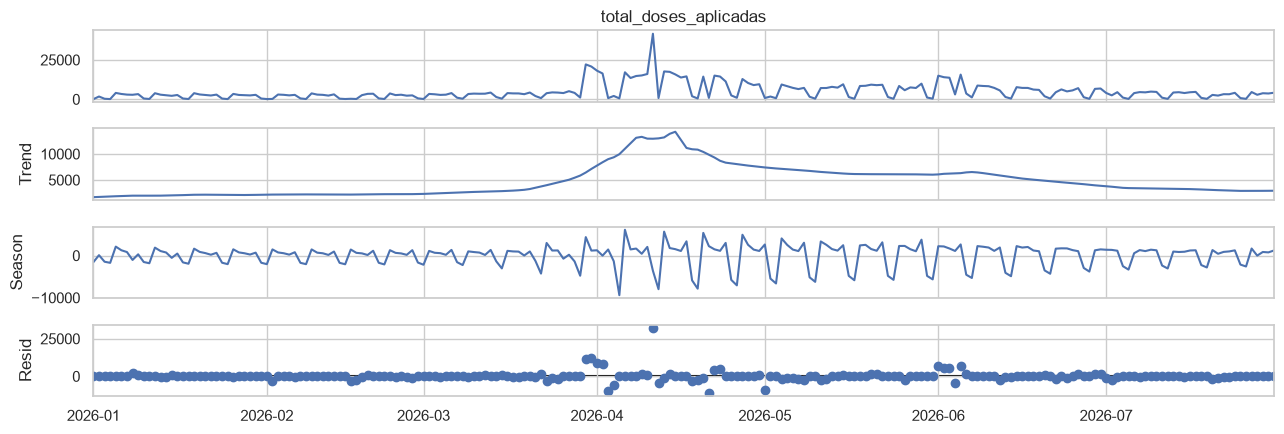

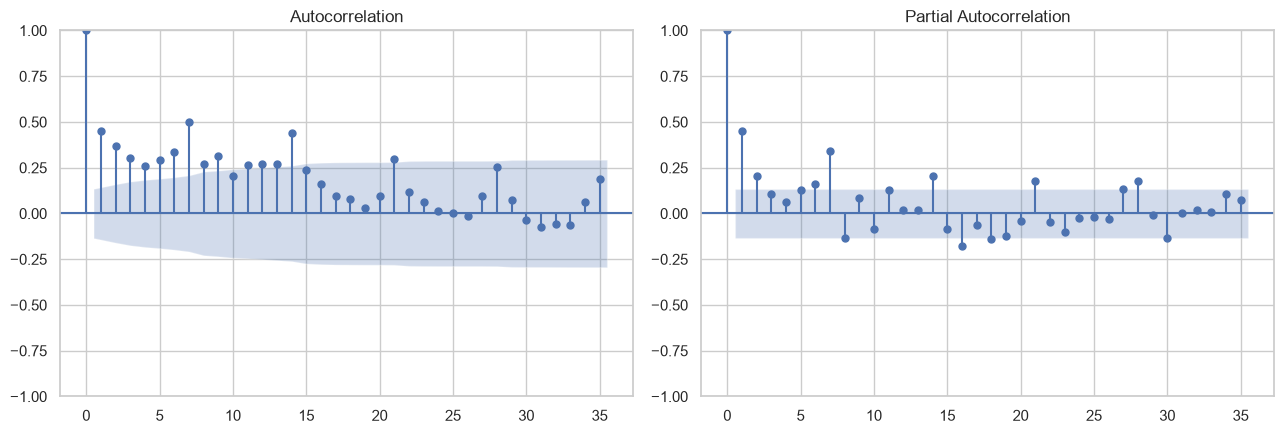

In [ ]:
stl = STL(serie_total, period=SAZONALIDADE, robust=True).fit()
stl.plot(); salvar("04_decomposicao_stl")

adf = adfuller(serie_total)
print(f"ADF p-valor = {adf[1]:.4f} →", "estacionária" if adf[1] < .05 else "não estacionária (diferenciar)")

fig, axs = plt.subplots(1, 2)
plot_acf(serie_total, lags=35, ax=axs[0]); plot_pacf(serie_total, lags=35, ax=axs[1]); salvar("05_acf_pacf")

## 6. Divisão temporal treino/teste
Sem embaralhar: as últimas `HORIZONTE` observações são o teste.

In [ ]:
def split(s, h=HORIZONTE): return s.iloc[:-h], s.iloc[-h:]
tr, te = split(serie_total)
print(f"Treino: {tr.index.min().date()} → {tr.index.max().date()} ({len(tr)} dias)")
print(f"Teste : {te.index.min().date()} → {te.index.max().date()} ({len(te)} dias)")

Treino: 2026-01-01 → 2026-07-03 (184 dias)
Teste : 2026-07-04 → 2026-07-31 (28 dias)


## 7. Métricas e Baselines

In [ ]:
def metricas(y, yhat):
    y, yhat = np.asarray(y, float), np.clip(np.asarray(yhat, float), 0, None)
    smape = np.mean(2*np.abs(yhat-y) / np.where((np.abs(y)+np.abs(yhat))==0, 1, np.abs(y)+np.abs(yhat))) * 100
    return {"MAE": mean_absolute_error(y, yhat),
            "RMSE": np.sqrt(mean_squared_error(y, yhat)),
            "sMAPE_%": smape}

def baseline_naive(tr, h):          return np.repeat(tr.iloc[-1], h)
def baseline_sazonal(tr, h, s=SAZONALIDADE):  # repete a última semana
    return np.resize(tr.iloc[-s:].values, h)
def baseline_media_dow(tr, h):      # média por dia da semana nas últimas 4 semanas
    ult = tr.iloc[-28:]; m = ult.groupby(ult.index.dayofweek).mean()
    idx = pd.date_range(tr.index[-1] + pd.Timedelta(days=1), periods=h)
    return m.reindex(idx.dayofweek).values

## 8. ARIMA / SARIMA
Busca em grade pequena por AIC, com sazonalidade semanal `s=7`.

SARIMA(2, 1, 1)x(1, 1, 1, 7)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0850      0.089      0.952      0.341      -0.090       0.260
ar.L2          0.1123      0.130      0.864      0.388      -0.143       0.367
ma.L1         -0.8231      0.076    -10.785      0.000      -0.973      -0.674
ar.S.L7       -0.0656      0.066     -0.995      0.320      -0.195       0.064
ma.S.L7       -0.8528      0.061    -13.952      0.000      -0.973      -0.733
sigma2      1.882e+07   7.63e-09   2.47e+15      0.000    1.88e+07    1.88e+07


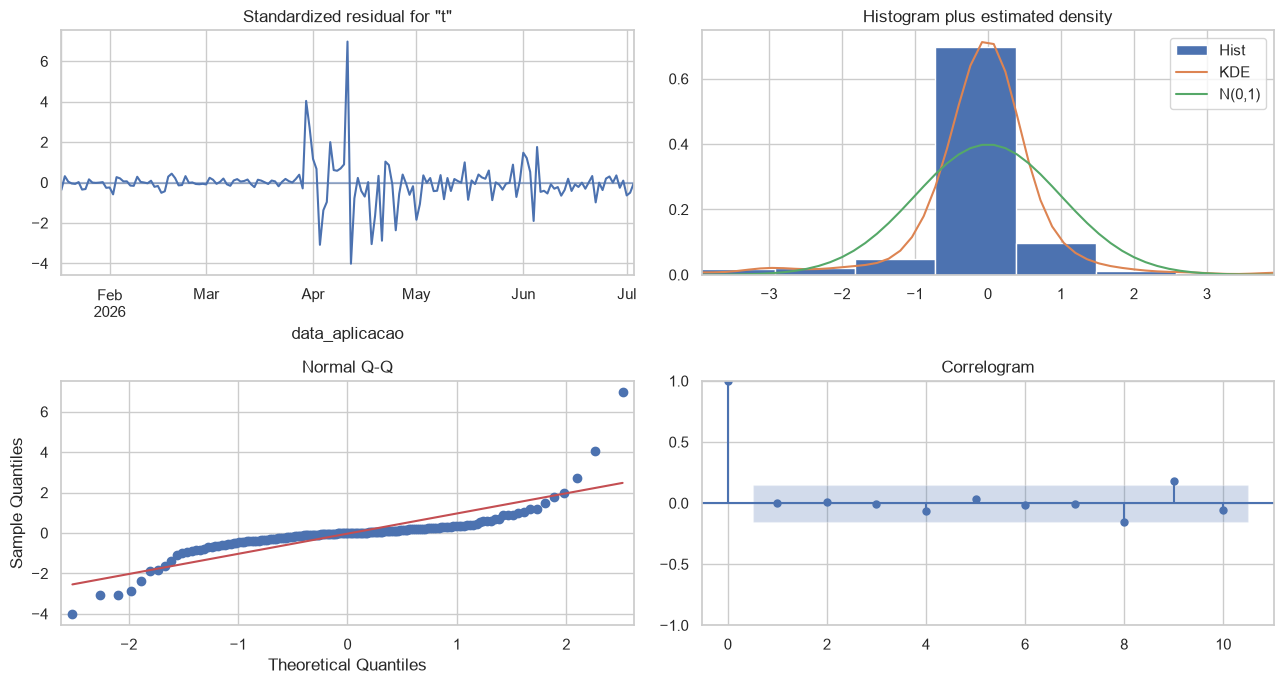

In [ ]:
def ajustar_sarima(tr, s=SAZONALIDADE):
    melhor = (np.inf, None, None)
    for p, d, q in itertools.product(range(3), range(2), range(3)):
        for P, D, Q in itertools.product(range(2), range(2), range(2)):
            try:
                m = SARIMAX(tr, order=(p,d,q), seasonal_order=(P,D,Q,s),
                            enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
                if m.aic < melhor[0]: melhor = (m.aic, (p,d,q), (P,D,Q,s), m)
            except Exception: pass
    return melhor[3], melhor[1], melhor[2]

def prev_sarima(tr, h):
    m, o, so = ajustar_sarima(tr)
    return m.forecast(h).values, f"SARIMA{o}x{so}", m

yhat, nome, m_total = prev_sarima(tr, HORIZONTE)
print(nome); print(m_total.summary().tables[1])
m_total.plot_diagnostics(figsize=(13, 7)); salvar("06_sarima_diagnostico")

## 9. Prophet
Sazonalidade semanal + feriados nacionais (BR). Sazonalidade anual desligada: há menos de 1 ano de dados.

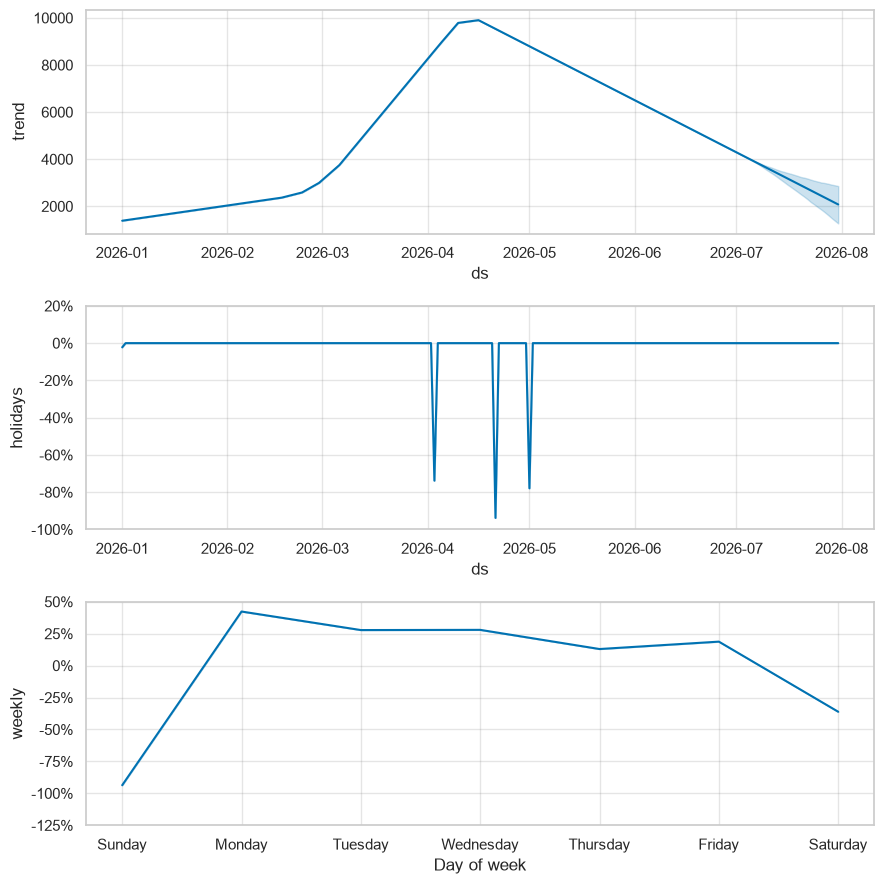

In [ ]:
from prophet import Prophet
import holidays as hol
import logging
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
logging.getLogger("cmdstanpy").disabled = True


# Tabela de feriados BR, sem repetições
anos = range(tr.index.min().year, tr.index.max().year + 2)
feriados_br = pd.DataFrame(
    [(pd.Timestamp(d), nome) for d, nome in hol.Brazil(years=anos).items()],
    columns=["ds", "holiday"]
).drop_duplicates(subset="ds").reset_index(drop=True)

def prev_prophet(tr, h, retornar_modelo=False):
    d = tr.astype(float).rename_axis("ds").reset_index(name="y")
    m = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False,
                seasonality_mode="multiplicative", changepoint_prior_scale=0.1,
                holidays=feriados_br)
    m.fit(d)
    fc = m.predict(m.make_future_dataframe(periods=h, include_history=False))
    return (fc, m) if retornar_modelo else fc["yhat"].values

fc, m_p = prev_prophet(tr, HORIZONTE, retornar_modelo=True)
m_p.plot_components(m_p.predict(m_p.make_future_dataframe(HORIZONTE))); salvar("07_prophet_componentes")


## 10. Comparação dos modelos (todas as séries)

In [ ]:
resultados, previsoes = [], {}
for nome_serie, s in series.items():
    tr, te = split(s)
    prevs = {"Naive": baseline_naive(tr, HORIZONTE),
             "Sazonal ingênuo (7d)": baseline_sazonal(tr, HORIZONTE),
             "Média dia-semana 4sem": baseline_media_dow(tr, HORIZONTE)}
    sar, nome_sar, _ = prev_sarima(tr, HORIZONTE); prevs["SARIMA"] = sar
    prevs["Prophet"] = prev_prophet(tr, HORIZONTE)
    previsoes[nome_serie] = (tr, te, prevs)
    for modelo, yhat in prevs.items():
        resultados.append({"serie": nome_serie, "modelo": modelo,
                           "especificacao": nome_sar if modelo == "SARIMA" else "", **metricas(te, yhat)})
    print("ok:", nome_serie)

res = pd.DataFrame(resultados)
display(res.pivot(index="serie", columns="modelo", values="RMSE").round(1))
melhor = res.loc[res.groupby("serie")["RMSE"].idxmin(), ["serie","modelo","MAE","RMSE","sMAPE_%"]]
display(melhor.round(2))
res.to_csv("../reports/resultados_series_temporais.csv", index=False)

ok: TOTAL
ok: INF3
ok: INF4
ok: COV-19 PFIZER-COMIRN
ok: HB
ok: dT


modelo,Média dia-semana 4sem,Naive,Prophet,SARIMA,Sazonal ingênuo (7d)
serie,,,,,
COV-19 PFIZER-COMIRN,219.8,178.9,193.1,360.8,102.7
HB,29.7,117.3,25.2,25.9,34.7
INF3,1677.9,880.2,856.9,547.9,1037.3
INF4,77.5,47.8,68.7,53.7,43.5
TOTAL,2215.1,2224.7,906.0,969.8,1803.5
dT,26.1,113.5,21.5,24.2,49.5


,serie,modelo,MAE,RMSE,sMAPE_%
16,COV-19 PFIZER-COMIRN,Sazonal ingênuo (7d),72.36,102.71,33.40
24,HB,Prophet,19.26,25.17,11.25
8,INF3,SARIMA,419.32,547.85,84.69
11,INF4,Sazonal ingênuo (7d),37.00,43.48,55.18
4,TOTAL,Prophet,736.86,906.01,30.62
29,dT,Prophet,16.27,21.50,10.71


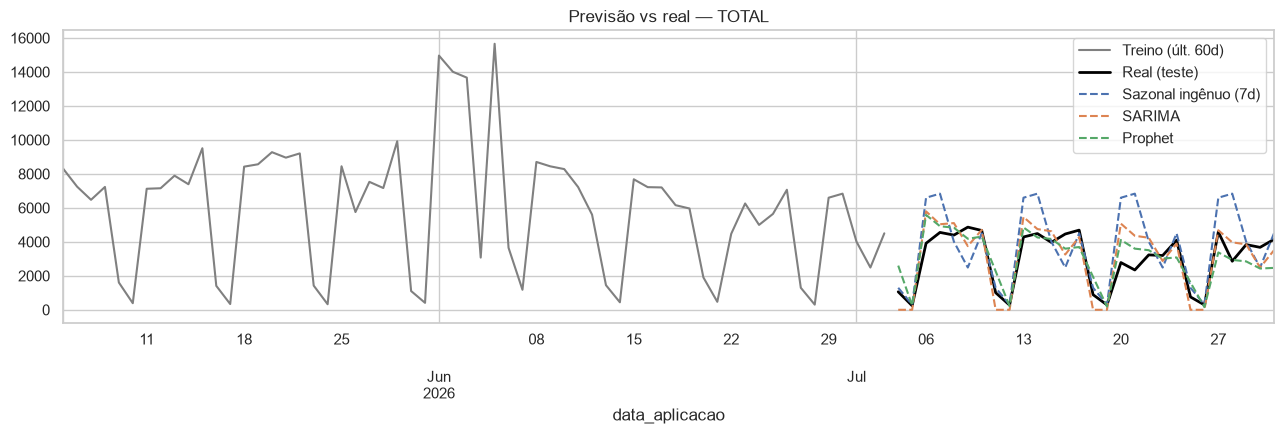

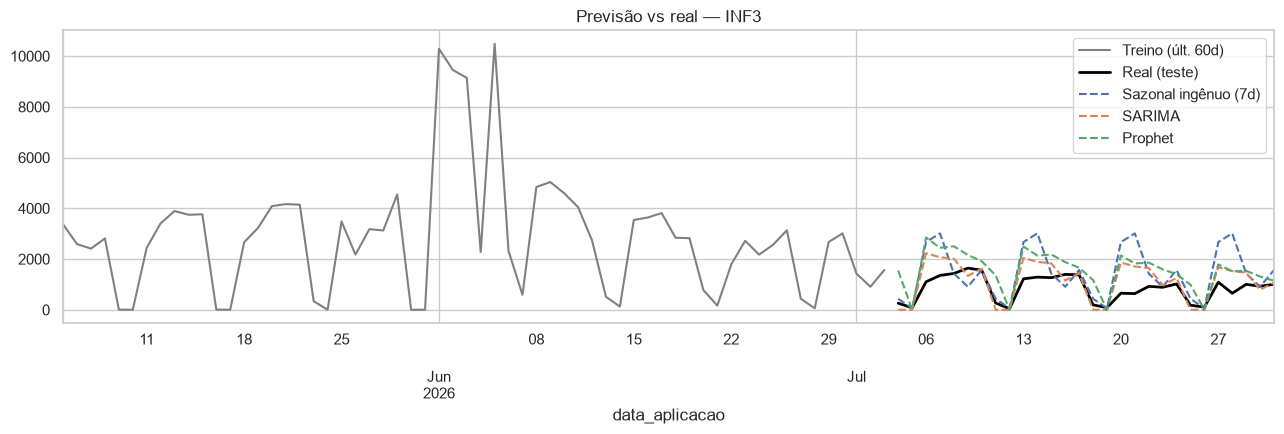

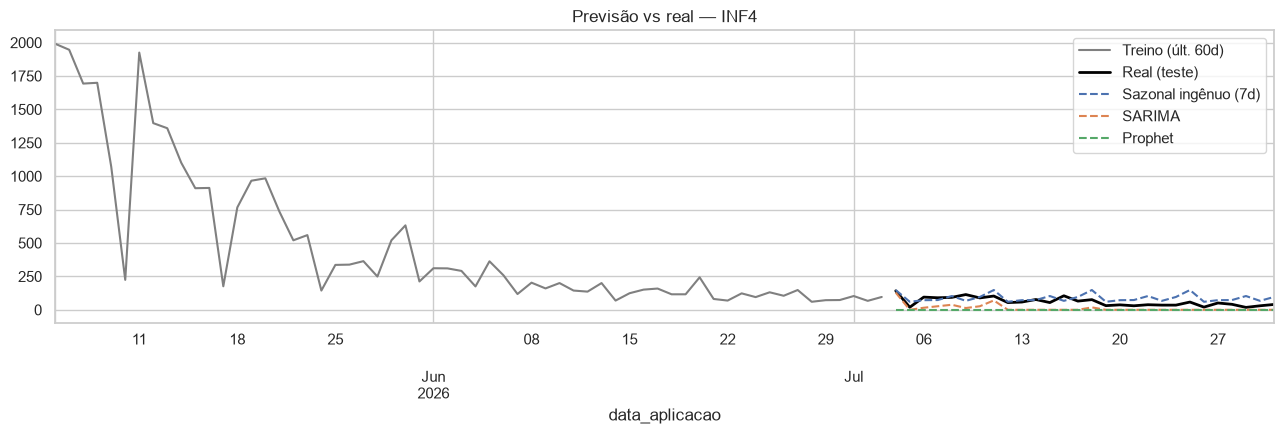

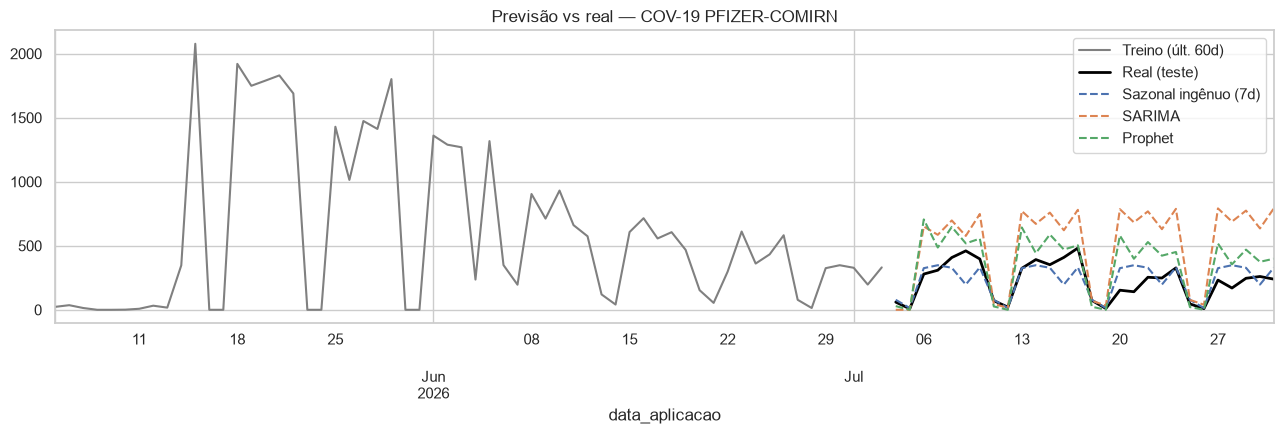

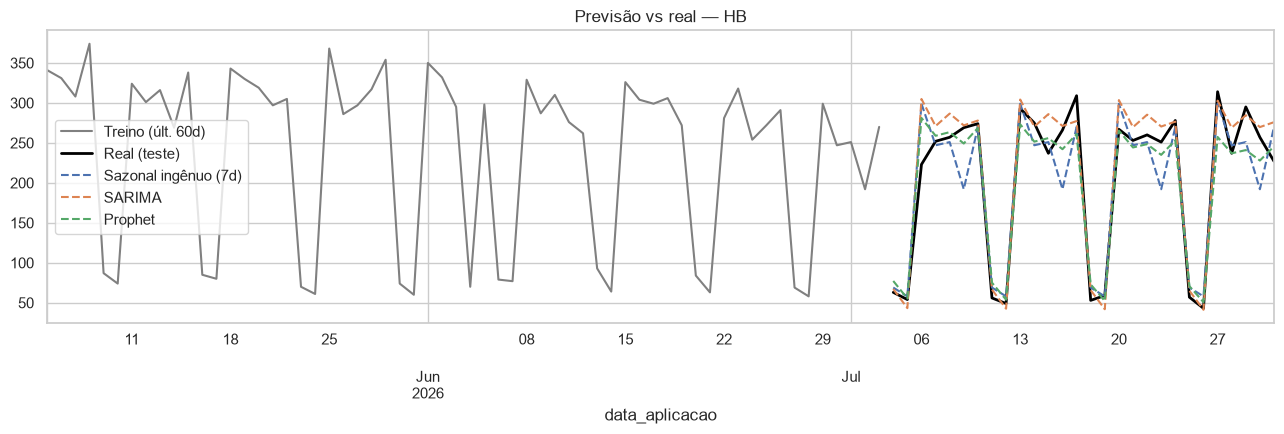

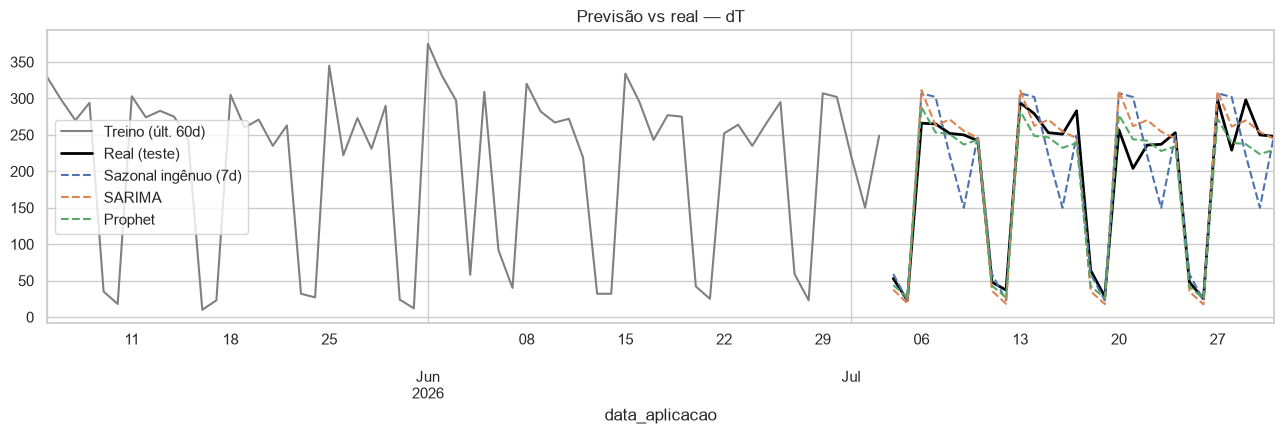

In [ ]:
for nome_serie, (tr, te, prevs) in previsoes.items():
    fig, ax = plt.subplots()
    tr.iloc[-60:].plot(ax=ax, color="gray", label="Treino (últ. 60d)")
    te.plot(ax=ax, color="black", lw=2, label="Real (teste)")
    for mod in ["Sazonal ingênuo (7d)", "SARIMA", "Prophet"]:
        ax.plot(te.index, np.clip(prevs[mod], 0, None), "--", label=mod)
    ax.set_title(f"Previsão vs real — {nome_serie}"); ax.legend()
    salvar(f"08_prev_{str(nome_serie)[:30].replace(' ','_').replace('/','-')}")

## 11. Previsão futura com o melhor modelo (reajustado com a série completa)

In [ ]:
futuro = {}
for _, r in melhor.iterrows():
    s = series[r.serie]
    if r.modelo == "Prophet":  yhat = prev_prophet(s, HORIZONTE)
    elif r.modelo == "SARIMA": yhat = prev_sarima(s, HORIZONTE)[0]
    elif r.modelo == "Naive":  yhat = baseline_naive(s, HORIZONTE)
    elif r.modelo.startswith("Sazonal"): yhat = baseline_sazonal(s, HORIZONTE)
    else: yhat = baseline_media_dow(s, HORIZONTE)
    futuro[r.serie] = np.clip(yhat, 0, None).round()
idx = pd.date_range(serie_total.index[-1] + pd.Timedelta(days=1), periods=HORIZONTE)
df_futuro = pd.DataFrame(futuro, index=idx); display(df_futuro.head(14))
df_futuro.to_csv("../reports/previsao_proximas_semanas.csv")

,COV-19 PFIZER-COMIRN,HB,INF3,INF4,TOTAL,dT
2026-08-01,46,70.0,0.0,58,1240.0,43.0
2026-08-02,9,51.0,0.0,20,72.0,26.0
2026-08-03,232,262.0,1155.0,51,2656.0,276.0
2026-08-04,170,241.0,1047.0,41,2359.0,243.0
2026-08-05,246,246.0,1056.0,18,2211.0,243.0
2026-08-06,260,234.0,625.0,30,1883.0,229.0
2026-08-07,239,251.0,820.0,40,1977.0,235.0
2026-08-08,46,69.0,0.0,58,927.0,42.0
2026-08-09,9,50.0,0.0,20,53.0,26.0
2026-08-10,232,256.0,954.0,51,1934.0,272.0


## 12. Interpretação e limitações
- **Sazonalidade semanal** domina a série (queda em sáb/dom): baselines sazonais são o piso a ser superado — se SARIMA/Prophet não vencem o *sazonal ingênuo*, isso deve ser reportado.
- **Campanhas** (ex.: Influenza) geram picos não recorrentes em menos de 1 ano de dados; o modelo não "conhece" campanhas futuras. Possível melhoria: regressores de campanha no Prophet.
- **Atraso de registro**: os últimos dias podem estar subnotificados; considere descartá-los antes do split.
- Prevê **doses aplicadas**, não cobertura vacinal (sem denominador populacional — mesma ressalva do clustering).